# Task 1: Multi-Class Benchmark Classification Pipeline (Iris)
**Goal:** Build an end-to-end classification pipeline with Scikit-Learn, feature scaling, and confusion matrices.

**Pipeline:** Load data → EDA (pairplot) → 80/20 split → StandardScaler → Logistic Regression & Decision Tree → Metrics → Confusion matrices → Decision boundaries

## 1. Imports

In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from sklearn.datasets import load_iris
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler
from sklearn.linear_model import LogisticRegression
from sklearn.tree import DecisionTreeClassifier
from sklearn.metrics import (accuracy_score, precision_score, recall_score,
                             f1_score, confusion_matrix, classification_report)

sns.set_style("whitegrid")
RANDOM_STATE = 42

## 2. Load the dataset with Pandas

In [2]:
iris = load_iris(as_frame=True)
df = iris.frame.copy()
df["species"] = df["target"].map(dict(enumerate(iris.target_names)))
feature_cols = iris.feature_names
class_names = list(iris.target_names)

print("Shape:", df.shape)
display(df.head())
display(df.describe().round(2))
print("Missing values per column:")
print(df.isna().sum())
print("\nClass balance:")
print(df["species"].value_counts())

Shape: (150, 6)


,sepal length (cm),sepal width (cm),petal length (cm),petal width (cm),target,species
0,5.1,3.5,1.4,0.2,0,setosa
1,4.9,3.0,1.4,0.2,0,setosa
2,4.7,3.2,1.3,0.2,0,setosa
3,4.6,3.1,1.5,0.2,0,setosa
4,5.0,3.6,1.4,0.2,0,setosa


,sepal length (cm),sepal width (cm),petal length (cm),petal width (cm),target
count,150.00,150.00,150.00,150.00,150.00
mean,5.84,3.06,3.76,1.20,1.00
std,0.83,0.44,1.77,0.76,0.82
min,4.30,2.00,1.00,0.10,0.00
25%,5.10,2.80,1.60,0.30,0.00
50%,5.80,3.00,4.35,1.30,1.00
75%,6.40,3.30,5.10,1.80,2.00
max,7.90,4.40,6.90,2.50,2.00


Missing values per column:
sepal length (cm)    0
sepal width (cm)     0
petal length (cm)    0
petal width (cm)     0
target               0
species              0
dtype: int64

Class balance:
species
setosa        50
versicolor    50
virginica     50
Name: count, dtype: int64


## 3. Exploratory pairplot (Seaborn)

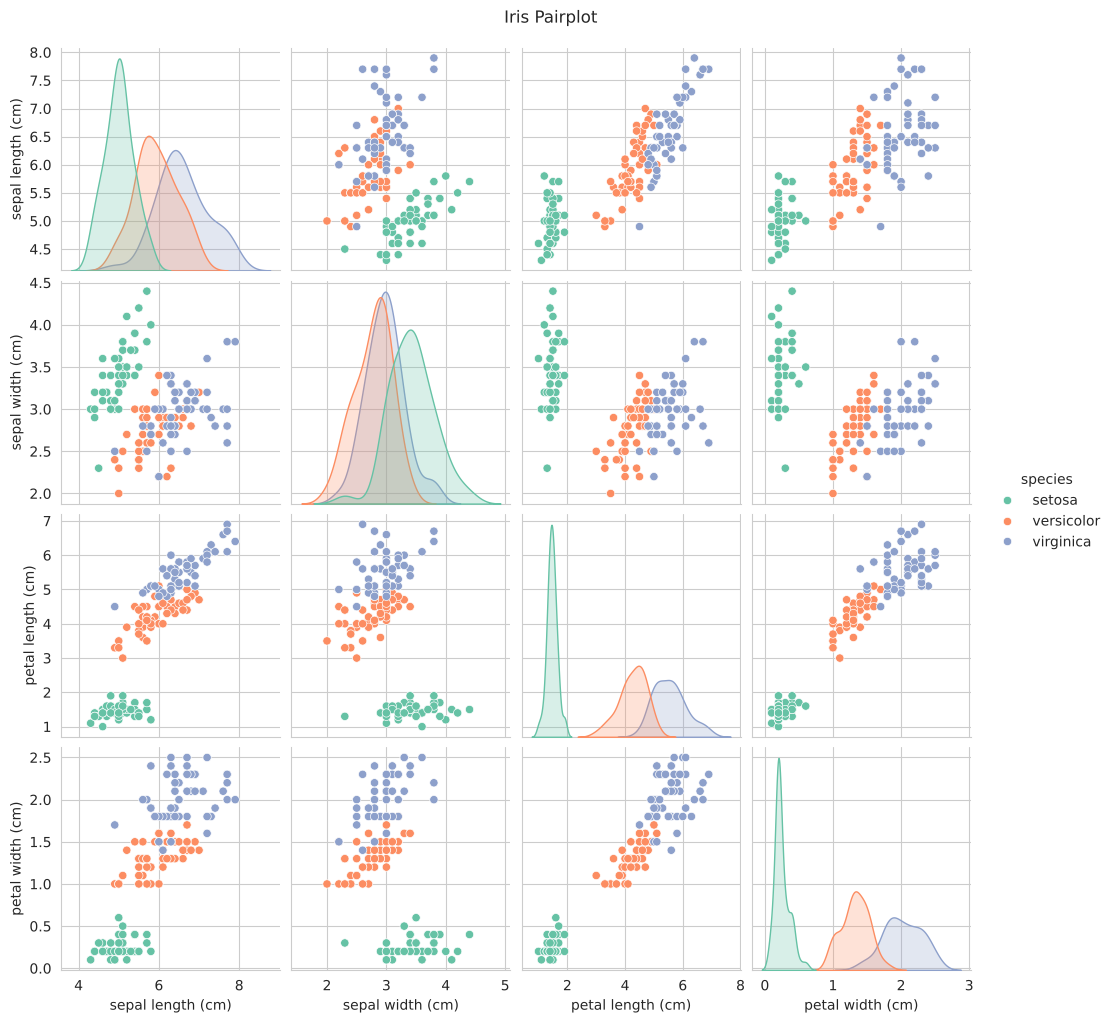

In [3]:
pp = sns.pairplot(df.drop(columns="target"), hue="species", diag_kind="kde", palette="Set2")
pp.fig.suptitle("Iris Pairplot", y=1.02)
plt.show()

**Observation:** Setosa is clearly separable from the other two classes. Versicolor and virginica overlap, mainly in sepal dimensions, while the petal features separate them best.

## 4. Train/test split (80/20) and feature scaling
The split is stratified to keep class proportions equal. The scaler is **fit on the training set only** and then applied to the test set to avoid data leakage.

In [4]:
X = df[feature_cols]
y = df["target"]

X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.20, random_state=RANDOM_STATE, stratify=y)

scaler = StandardScaler()
X_train_s = scaler.fit_transform(X_train)
X_test_s = scaler.transform(X_test)

print("Train:", X_train_s.shape, "| Test:", X_test_s.shape)
print("Scaled train mean (≈0):", X_train_s.mean(axis=0).round(3))
print("Scaled train std  (≈1):", X_train_s.std(axis=0).round(3))

Train: (120, 4) | Test: (30, 4)
Scaled train mean (≈0): [-0.  0.  0.  0.]
Scaled train std  (≈1): [1. 1. 1. 1.]


## 5. Train Logistic Regression and Decision Tree

In [5]:
models = {
    "Logistic Regression": LogisticRegression(max_iter=1000, random_state=RANDOM_STATE),
    "Decision Tree": DecisionTreeClassifier(max_depth=4, random_state=RANDOM_STATE),
}

preds, results = {}, []
for name, model in models.items():
    model.fit(X_train_s, y_train)
    y_pred = model.predict(X_test_s)
    preds[name] = y_pred
    results.append({
        "Model": name,
        "Accuracy": accuracy_score(y_test, y_pred),
        "Precision (macro)": precision_score(y_test, y_pred, average="macro", zero_division=0),
        "Recall (macro)": recall_score(y_test, y_pred, average="macro", zero_division=0),
        "F1 (macro)": f1_score(y_test, y_pred, average="macro", zero_division=0),
    })

## 6. Classification reports

In [6]:
for name, y_pred in preds.items():
    print(f"=== {name} ===")
    print(classification_report(y_test, y_pred, target_names=class_names, zero_division=0))

=== Logistic Regression ===
              precision    recall  f1-score   support

      setosa       1.00      1.00      1.00        10
  versicolor       0.90      0.90      0.90        10
   virginica       0.90      0.90      0.90        10

    accuracy                           0.93        30
   macro avg       0.93      0.93      0.93        30
weighted avg       0.93      0.93      0.93        30

=== Decision Tree ===
              precision    recall  f1-score   support

      setosa       1.00      1.00      1.00        10
  versicolor       0.90      0.90      0.90        10
   virginica       0.90      0.90      0.90        10

    accuracy                           0.93        30
   macro avg       0.93      0.93      0.93        30
weighted avg       0.93      0.93      0.93        30



## 7. Benchmark summary

,Accuracy,Precision (macro),Recall (macro),F1 (macro)
Model,,,,
Logistic Regression,0.9333,0.9333,0.9333,0.9333
Decision Tree,0.9333,0.9333,0.9333,0.9333


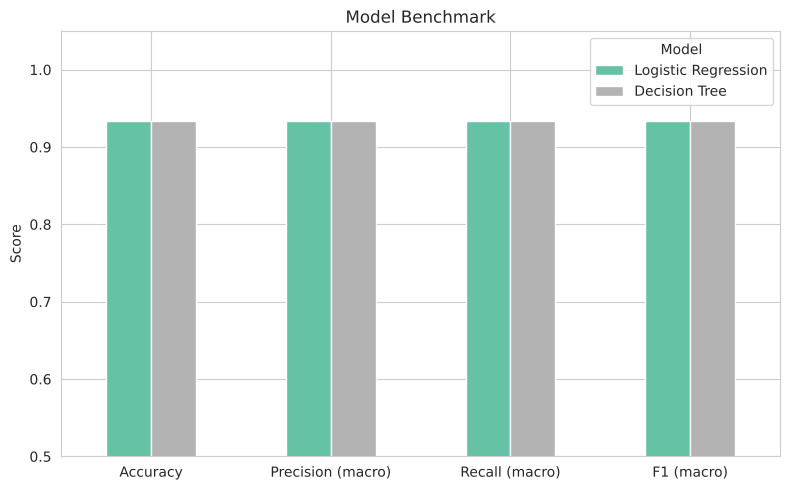

In [7]:
results_df = pd.DataFrame(results).set_index("Model").round(4)
display(results_df)

ax = results_df.T.plot(kind="bar", figsize=(8, 5), colormap="Set2", rot=0)
ax.set_ylim(0.5, 1.05)
ax.set_title("Model Benchmark")
ax.set_ylabel("Score")
plt.tight_layout()
plt.show()

## 8. Confusion matrix heatmaps

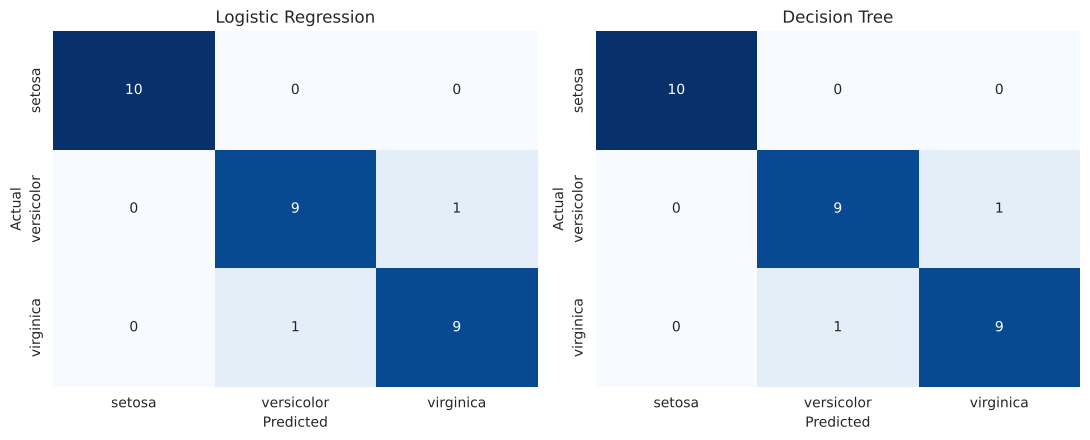

In [8]:
fig, axes = plt.subplots(1, 2, figsize=(11, 4.5))
for ax, (name, y_pred) in zip(axes, preds.items()):
    cm = confusion_matrix(y_test, y_pred)
    sns.heatmap(cm, annot=True, fmt="d", cmap="Blues", cbar=False,
                xticklabels=class_names, yticklabels=class_names, ax=ax)
    ax.set_title(name)
    ax.set_xlabel("Predicted")
    ax.set_ylabel("Actual")
plt.tight_layout()
plt.show()

## 9. Decision boundary visualization
A boundary can only be drawn in 2D, so both models are retrained on **petal length** and **petal width** (the most discriminative features) for visualization only.

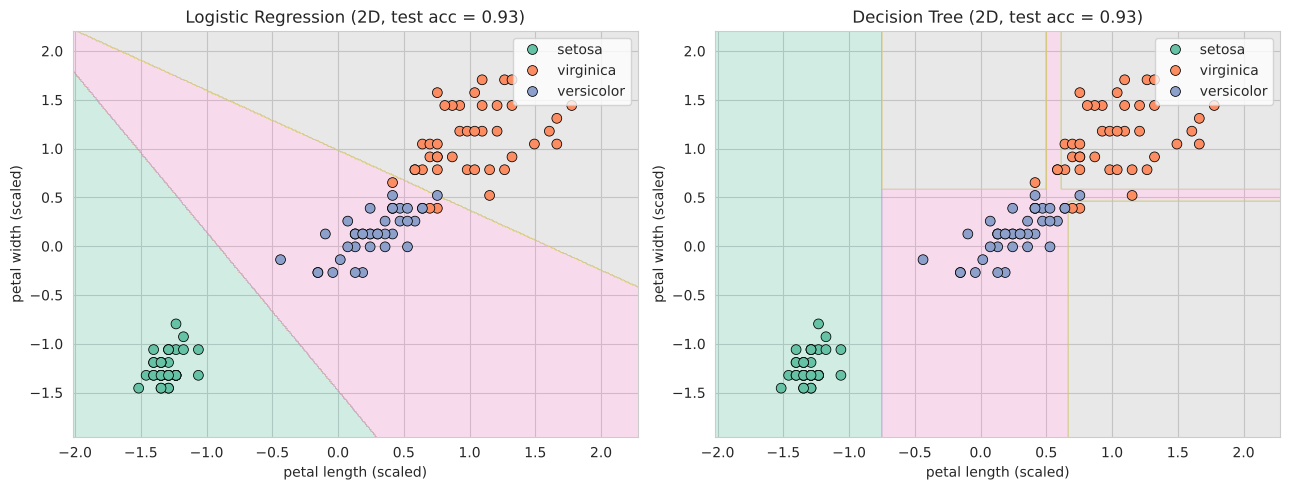

In [9]:
viz_features = ["petal length (cm)", "petal width (cm)"]
scaler_v = StandardScaler().fit(X_train[viz_features])
Xv_train_s = scaler_v.transform(X_train[viz_features])
Xv_test_s = scaler_v.transform(X_test[viz_features])

fig, axes = plt.subplots(1, 2, figsize=(13, 5))
for ax, (name, model) in zip(axes, models.items()):
    m2d = type(model)(**model.get_params()).fit(Xv_train_s, y_train)
    acc2d = accuracy_score(y_test, m2d.predict(Xv_test_s))

    x_min, x_max = Xv_train_s[:, 0].min() - 0.5, Xv_train_s[:, 0].max() + 0.5
    y_min, y_max = Xv_train_s[:, 1].min() - 0.5, Xv_train_s[:, 1].max() + 0.5
    xx, yy = np.meshgrid(np.linspace(x_min, x_max, 400), np.linspace(y_min, y_max, 400))
    Z = m2d.predict(np.c_[xx.ravel(), yy.ravel()]).reshape(xx.shape)

    ax.contourf(xx, yy, Z, alpha=0.3, cmap="Set2")
    sns.scatterplot(x=Xv_train_s[:, 0], y=Xv_train_s[:, 1],
                    hue=[class_names[i] for i in y_train], palette="Set2",
                    edgecolor="k", s=50, ax=ax)
    ax.set_title(f"{name} (2D, test acc = {acc2d:.2f})")
    ax.set_xlabel("petal length (scaled)")
    ax.set_ylabel("petal width (scaled)")
plt.tight_layout()
plt.show()

## 10. Conclusion
- Both models reach the same test accuracy, precision, recall and F1 on this split. Setosa is classified perfectly; the only errors are between versicolor and virginica, which overlap in feature space.
- Logistic Regression produces linear (straight-line) decision boundaries, while the Decision Tree produces axis-aligned rectangular regions.
- `StandardScaler` matters for Logistic Regression (gradient-based optimization), while Decision Trees are scale-invariant.
- With only 30 test samples, one misclassification changes accuracy by about 3.3 points, so cross-validation would give a more reliable comparison.